# 04 - FST and variance partitioning: how different are the groups, really?

$F_{ST}$ measures the share of genetic variation that separates populations.
For a biallelic SNP, a simple way to think about it is:

$$ F_{ST} \approx \frac{\text{variance in allele frequency between populations}}
{\text{total variance in allele frequency}} $$

We use **Hudson's estimator**, which is what `plink2 --fst` reports and which
is robust to unequal sample sizes:

$$ \hat{F}_{ST} = \frac{(p_1 - p_2)^2 - \frac{p_1(1-p_1)}{n_1-1} - \frac{p_2(1-p_2)}{n_2-1}}
{p_1(1-p_2) + p_2(1-p_1)} $$

Typical scales: ~0.15 between continents, ~0.005-0.02 between European
countries, and ~0.0005-0.002 between closely related neighbouring
populations - exactly our situation.

This notebook:

1. computes pairwise FST between the Balkan groups and nearby populations,
2. asks the central question directly: **do nation labels separate the 70
   GEO samples more than random labels would?** (permutation test), and
3. compares between-nation FST with within-nation FST (random splits).

In [1]:
from pathlib import Path
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
import poreklo_io as pio

FIG = ROOT / "results" / "figures"
TAB = ROOT / "results" / "tables"
NB04 = ROOT / "data" / "processed" / "nb04"
NB04.mkdir(parents=True, exist_ok=True)
meta = pd.read_csv(ROOT / "data" / "metadata" / "modern_merged_samples.tsv", sep="\t")
group_of = dict(zip(meta["iid"], meta["group"]))
balkan = ["Bosniac", "Bosnian_Serb", "Serbian", "Montenegrin", "Macedonian", "Kosovar"]
neighbours = ["Croatian", "Bulgarian", "Greek", "Albanian", "Romanian", "Turkish", "TSI"]
ANALYSIS = ROOT / "data" / "processed" / "nb01" / "analysis"

## 1. Pairwise FST between labelled groups

`plink2 --fst` wants a categorical phenotype. We write a small phenotype file
from the sample metadata and select neighbouring reference populations.

In [2]:
selected = balkan + neighbours
pheno = NB04 / "pheno.txt"
with open(pheno, "w") as handle:
    handle.write("FID IID group\n")
    for line in open(str(ANALYSIS) + ".fam"):
        fields = line.split()
        group = group_of.get(fields[1])
        if group in selected:
            handle.write(f"{fields[0]} {fields[1]} {group}\n")

result = subprocess.run(["plink2", "--bfile", ANALYSIS, "--pheno", pheno, "--fst", "group",
                         "--out", NB04 / "fst"], cwd=ROOT, capture_output=True, text=True)
if result.returncode:
    print(result.stdout[-2000:], result.stderr[-2000:])
    result.check_returncode()

fst = pd.read_csv(NB04 / "fst.fst.summary", sep=r"\s+").rename(columns={"#POP1": "POP1"})
pops = sorted(set(fst["POP1"]) | set(fst["POP2"]))
mat = pd.DataFrame(np.nan, index=pops, columns=pops)
for _, row in fst.iterrows():
    mat.loc[row["POP1"], row["POP2"]] = row["HUDSON_FST"]
    mat.loc[row["POP2"], row["POP1"]] = row["HUDSON_FST"]
mat.to_csv(TAB / "nb04_fst_matrix.tsv", sep="\t")
print(mat.round(4).loc[balkan, balkan].to_string())

              Bosniac  Bosnian_Serb  Serbian  Montenegrin  Macedonian  Kosovar
Bosniac           NaN        0.0008   0.0001       0.0013      0.0007   0.0022
Bosnian_Serb   0.0008           NaN   0.0005       0.0022      0.0010   0.0042
Serbian        0.0001        0.0005      NaN       0.0004      0.0004   0.0018
Montenegrin    0.0013        0.0022   0.0004          NaN      0.0015   0.0020
Macedonian     0.0007        0.0010   0.0004       0.0015         NaN   0.0018
Kosovar        0.0022        0.0042   0.0018       0.0020      0.0018      NaN


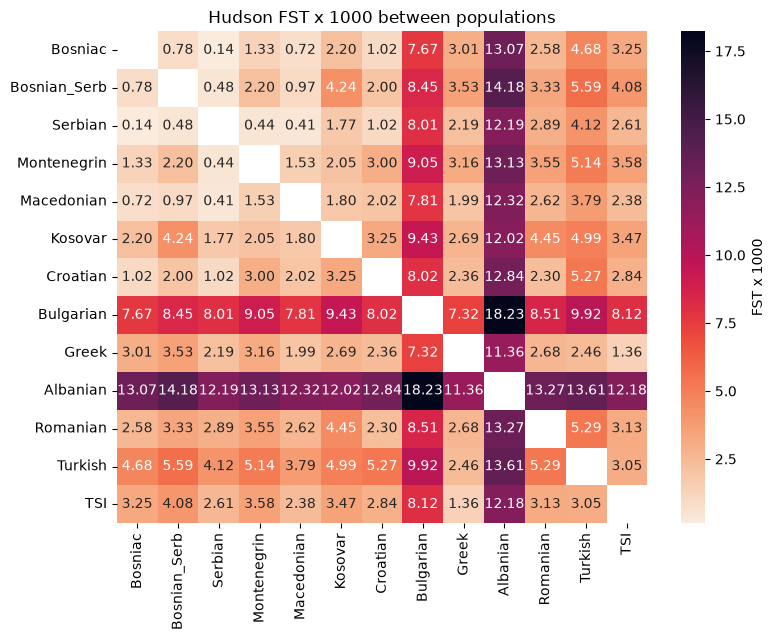

In [3]:
order = balkan + neighbours
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(mat.loc[order, order] * 1000, annot=True, fmt=".2f", cmap="rocket_r",
            cbar_kws={"label": "FST x 1000"}, ax=ax)
ax.set_title("Hudson FST x 1000 between populations")
fig.tight_layout(); fig.savefig(FIG / "nb04_fst_heatmap.png", dpi=130); plt.show()

Note the scale: within Bosnia (Bosniac, Bosnian_Serb) and against Croatians
and Macedonians, values are around **0.001-0.003** - one to two orders of
magnitude smaller than the ~0.01-0.02 seen against Albanians or TSI.

**Caveat:** GEO and AADR samples were genotyped in different studies on
different arrays. Cross-source FST can contain technical batch effects, so
treat the GEO-vs-panel numbers as upper bounds; the GEO-vs-GEO values below
are clean.

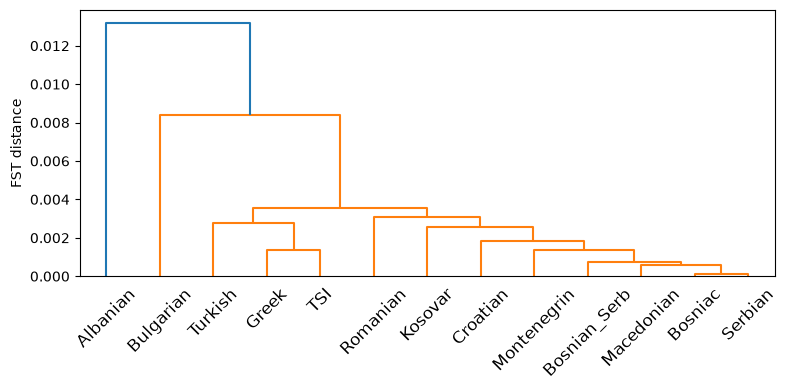

In [4]:
condensed = squareform(mat.loc[order, order].to_numpy(), checks=False)
tree = linkage(condensed, method="average")
fig, ax = plt.subplots(figsize=(8, 4))
dendrogram(tree, labels=order, ax=ax, leaf_rotation=45)
ax.set_ylabel("FST distance")
fig.tight_layout(); fig.savefig(FIG / "nb04_fst_tree.png", dpi=130); plt.show()

## 2. The direct question: do nations separate more than chance?

Now restrict to the 70 GEO samples, where there is no batch effect between
groups. We compute Hudson's FST between the six nation labels and then
**permute the labels**: if nations were irrelevant, the observed FST should
look like the permuted distribution.

GEO-only matrix: (72552, 70)
{'Bosniac': 15, 'Macedonian': 14, 'Montenegrin': 14, 'Serbian': 14, 'Kosovar': 9, 'Bosnian_Serb': 4}
observed among-nation FST: 0.001404


permutation p-value: 0.0010  (1000 label shuffles)


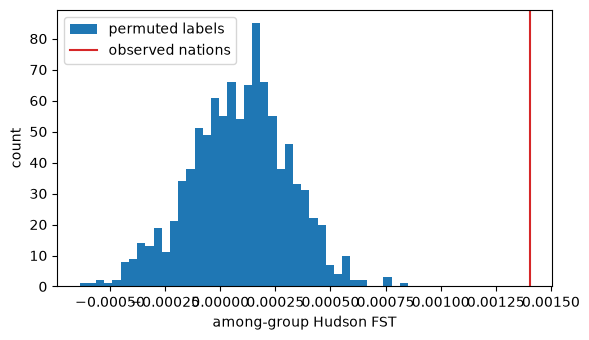

In [5]:
fam_all = pio.read_fam(str(ANALYSIS) + ".fam")
bim = pio.read_bim(str(ANALYSIS) + ".bim")
G = pio.read_bed_dosage(str(ANALYSIS) + ".bed", len(fam_all), len(bim))
geo_mask = np.array([s["iid"] in group_of and meta.set_index("iid").loc[s["iid"], "source"] == "geo"
                     for s in fam_all])
G_geo = G[:, geo_mask]
labels = np.array([group_of[s["iid"]] for s, keep in zip(fam_all, geo_mask) if keep])
print("GEO-only matrix:", G_geo.shape)
print(pd.Series(labels).value_counts().to_dict())

def hudson_fst(dos, labels, groups):
    """Mean pairwise Hudson FST over all pairs of the given groups (vectorized).

    dos: (n_snp, n_ind) int8 with -1 for missing
    labels: length n_ind array of group labels
    """
    G = dos.astype(np.float32)
    called = G >= 0
    G[~called] = 0.0
    flat = np.asarray(labels)
    indicator = np.zeros((len(flat), len(groups)), dtype=np.float32)
    for gi, group in enumerate(groups):
        indicator[:, gi] = (flat == group)
    counts = called.astype(np.float32) @ indicator  # called individuals per group
    sums = G @ indicator
    with np.errstate(divide="ignore", invalid="ignore"):
        p = sums / (2.0 * counts)
    total_num = total_den = 0.0
    for i in range(len(groups)):
        for j in range(i + 1, len(groups)):
            p1, p2 = p[:, i], p[:, j]
            n1, n2 = 2 * counts[:, i], 2 * counts[:, j]  # sampled chromosomes
            num = (p1 - p2) ** 2 - p1 * (1 - p1) / (n1 - 1) - p2 * (1 - p2) / (n2 - 1)
            den = p1 * (1 - p2) + p2 * (1 - p1)
            ok = (n1 > 1) & (n2 > 1) & np.isfinite(num) & np.isfinite(den) & (den > 0)
            total_num += float(num[ok].sum())
            total_den += float(den[ok].sum())
    return total_num / total_den

observed = hudson_fst(G_geo, labels, balkan)
print(f"observed among-nation FST: {observed:.6f}")

rng = np.random.default_rng(42)
null = np.empty(1000)
for r in range(len(null)):
    shuffled = rng.permutation(labels)
    null[r] = hudson_fst(G_geo, shuffled, balkan)
p_value = (1 + (null >= observed).sum()) / (len(null) + 1)
print(f"permutation p-value: {p_value:.4f}  (1000 label shuffles)")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(null, bins=40, label="permuted labels")
ax.axvline(observed, color="tab:red", label="observed nations")
ax.set_xlabel("among-group Hudson FST"); ax.set_ylabel("count"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "nb04_label_permutation.png", dpi=130); plt.show()

## 3. Between-nation vs. within-nation differentiation

A useful sanity baseline: split each nation randomly into two halves and
compute FST between the halves. If nation labels captured real separated
gene pools, between-nation FST should be clearly larger than within-nation
FST. (Nations with fewer than 8 samples are skipped.)

within-nation FST: mean -0.000024, 95% range [-0.001303, 0.000950]
between-nation FST: 0.001404


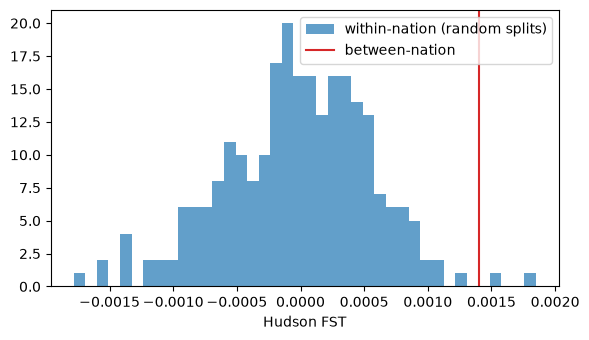

In [6]:
within = []
for group in balkan:
    idx = np.where(labels == group)[0]
    if len(idx) < 8:
        continue
    for r in range(50):
        perm = rng.permutation(idx)
        half = len(idx) // 2
        sub = np.array(["none"] * len(labels), dtype=object)
        sub[perm[:half]] = "A"
        sub[perm[half:]] = "B"
        within.append(hudson_fst(G_geo, sub, ["A", "B"]))
within = np.array(within)
print(f"within-nation FST: mean {within.mean():.6f}, 95% range "
      f"[{np.quantile(within, 0.025):.6f}, {np.quantile(within, 0.975):.6f}]")
print(f"between-nation FST: {observed:.6f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(within, bins=40, alpha=0.7, label="within-nation (random splits)")
ax.axvline(observed, color="tab:red", label="between-nation")
ax.set_xlabel("Hudson FST"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "nb04_within_between.png", dpi=130); plt.show()

## Reading the result

The output above tells a two-sided story:

1. **Nation labels are not nothing.** The observed between-nation FST
   (~0.0014) is larger than almost all label permutations (p ~ 0.001), so the
   labels carry a real, if faint, genetic signal.
2. **The signal is tiny.** An FST of ~0.0014 is roughly 100x smaller than the
   difference between European countries and continents, and random splits
   *within* a nation give FST values near zero that overlap heavily with the
   level of between-nation differences.

In other words: nations are not genetically irrelevant, but they explain only
a sliver of the variation, and the six groups are not separable units. Part of
the signal is probably geography (sampling towns differ between nations).
Notebook 06 separates nation from geography.

## Exercises

1. Replace nation labels with *country* labels (merge the three Bosnian
   groups) and rerun. Does country explain more than nation?
2. Use region/geography (sampling town) instead of nation in the permutation
   test. Which explains more?
3. How many permutations do you need for a stable p-value? Compare 1000 with
   10000.
4. Compute FST between the 35 GEO samples closest to the coast and the 35
   closest to the interior (use the coordinates from the paper). Is geography
   detectable even when nation is not?

Next: `05_kmeans.ipynb` does your original k-means idea, with a null model.